# Attention audit: map references and paired bridge sensitivities

Additional exploratory analyses, designed 2026-10-16 after the historical
E1/E2/RMS/bridge results were known. No training, inference or new intervention.
The old primary estimator and historical preregistration remain unchanged.

Read `plans/attention_audit_extension_20261016/PROTOCOL.md` first. Open this notebook,
select **Skripsi (.venv)**, then **Restart Kernel → Run All**. CPU only. Run All
creates a new run under `results/attention_audit_diagnostics/` and corresponding
`figures/attention_audit_diagnostics/`. No output exists until you run the cells.
Do not run notebooks 16/17/18 again to supply inputs; their pinned complete runs
are already available. Stop on failed alignment; do not change tolerances.

Builder: `.venv/bin/python scripts/build_nb_19.py` (generation only).
All scientific source is embedded below; the agent does not execute these cells.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from importlib.metadata import version
from itertools import combinations
import json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.spatial.distance import jensenshannon
from scipy.stats import rankdata
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'src/audit_e2.py').is_file())
PLAN = ROOT/'plans/attention_audit_extension_20261016'
BASELINE = ROOT/'results/e2/20261012T050124548170Z'
AMPLITUDE = ROOT/'results/e2_amplitude/20261014T024232464643Z'
BRIDGE = ROOT/'results/e1_e2_rms_bridge/20261014T041914953496Z'
EXPECTED_EVALUATION = 'c4b1d743f22d6b9bbbc5b2a2a8fcd7d913ba2543108895f8e70de9b4c1b79823'
EXPECTED_CONTROL = '1d839c2be1e4cc601eeaffc85acc7e380265bf076940f2a62b76648bee9a8ac7'
NOTEBOOK = ROOT/'notebooks/19_attention_audit_diagnostics.ipynb'
BUILDER = ROOT/'scripts/build_nb_19.py'
ANALYSIS_KIND = 'ATTENTION_STORED_DIAGNOSTICS_V1'
FAMILY = 'attention_audit_diagnostics'
DESIGN_DATE = '2026-10-16'
N_BOOT, BOOT_SEED, CONFIDENCE = 5000, 1902, .95
MIN_CI_SUBJECTS = 10
DENOM_FLOORS = (1e-8, 1e-6, 1e-4)
PRIMARY_FLOOR = DENOM_FLOORS[0]
METRICS = ('abs_delta_logit', 'signed_margin_drop', 'predicted_class_prob_drop')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT, FIG = ROOT/'results'/FAMILY/RUN_ID, ROOT/'figures'/FAMILY/RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG.mkdir(parents=True, exist_ok=False)
run_manifest = dict(run_id=RUN_ID,analysis_kind=ANALYSIS_KIND,analysis_design_date=DESIGN_DATE,
    completion_status='initializing',analysis_status='additional_exploratory',
    old_preregistration_changed=False,public_preregistration=False,training_performed=False,
    model_inference_performed=False,new_interventions_performed=False,
    baseline_run=BASELINE.name,amplitude_run=AMPLITUDE.name,bridge_run=BRIDGE.name)
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('New exploratory output:', OUT)

New exploratory output: /home/agribychaniago/Python Projects/Skripsi/results/attention_audit_diagnostics/20261016T045207091905Z


In [2]:
class AlignmentError(ValueError):
    pass

checks = []
tracked = {}

def file_hash(path):
    h = sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()

def source_digest(path):
    doc = json.loads(Path(path).read_text(encoding='utf-8'))
    sources = [dict(type=c['cell_type'],source=''.join(c.get('source',[]))) for c in doc['cells']]
    # Same content-only algorithm as notebook 17: include prose; exclude outputs.
    return sha256(json.dumps(sources,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def check(condition, name, detail=''):
    passed = bool(condition)
    checks.append(dict(check=name, passed=passed, detail=str(detail)))
    if not passed or len(checks)%1000==0:
        pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv', index=False)
    if not passed:
        run_manifest.update(completion_status='alignment_failed',failed_check=name,failed_detail=str(detail))
        (OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
        raise AlignmentError(name + ': ' + str(detail))

def track(path, expected=None):
    path = Path(path).resolve()
    check(path.is_file(), 'file exists', path.relative_to(ROOT))
    actual = file_hash(path)
    if expected is not None:
        check(actual==expected, 'SHA256', path.relative_to(ROOT))
    if path in tracked:
        check(tracked[path]==actual, 'source stable during preflight', path.relative_to(ROOT))
    tracked[path] = actual
    return actual

def read_csv(path):
    track(path)
    return pd.read_csv(path)

def bool_column(frame, name):
    text = frame[name].astype(str).str.lower()
    check(text.isin(['true','false']).all(), 'strict boolean '+name)
    frame[name] = text.eq('true')

def finite_close(a, b, name, atol=1e-8, rtol=1e-8):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and np.allclose(a, b, atol=atol, rtol=rtol, equal_nan=True), name)

def unique(frame, keys, name):
    check(not frame.duplicated(keys).any(), 'unique '+name, ','.join(keys))

def mask_hash(selected):
    return sha256(np.asarray(selected, dtype='<i8').tobytes()).hexdigest()

def keyed_seed(seed, *keys):
    # Exact baseline algorithm, including string conversion and JSON separators.
    key = json.dumps([int(seed), *map(str,keys)],separators=(',', ':'))
    return int.from_bytes(sha256(key.encode()).digest()[:8], 'little')

def attention_measures(a, b, fraction):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and a.ndim==1 and len(a)>=3, 'same alpha grid')
    check(np.isfinite(a).all() and np.isfinite(b).all() and (a>=0).all() and (b>=0).all(), 'alpha values')
    check(np.isclose(a.sum(),1,atol=1e-4,rtol=0) and np.isclose(b.sum(),1,atol=1e-4,rtol=0), 'alpha mass')
    a, b = a/a.sum(), b/b.sum()
    ra, rb = rankdata(a), rankdata(b)
    ra, rb = ra-ra.mean(), rb-rb.mean()
    den = np.linalg.norm(ra)*np.linalg.norm(rb)
    rho = float(np.clip(ra@rb/den, -1, 1)) if den>0 else np.nan
    def top_weights(alpha):
        k = max(1, int(np.ceil(len(alpha)*fraction)))
        cutoff = np.partition(alpha, len(alpha)-k)[len(alpha)-k]
        above, boundary = alpha>cutoff, alpha==cutoff
        out = above.astype(float)
        out[boundary] = (k-above.sum())/boundary.sum()
        return out
    wa, wb = top_weights(a), top_weights(b)
    return dict(js_divergence=float(np.clip(jensenshannon(a,b,base=2)**2,0,1)),
                rank_disagreement=(1-rho)/2 if np.isfinite(rho) else np.nan,
                top_jaccard_fractional=float(np.minimum(wa,wb).sum()/np.maximum(wa,wb).sum()))

In [3]:
pins = json.loads((PLAN/'source_pins.json').read_text())
track(PLAN/'source_pins.json')
track(PLAN/'PROTOCOL.md', pins['protocol_sha256'])
for rel, expected in pins['input_sha256'].items():
    track(ROOT/rel, expected)
track(ROOT/'scripts/build_nb_19.py')

'508a1e6ac00f81e22748c0e38736f7035cdb2cf3bd7884285932b04661b2f456'

In [4]:
track(BASELINE/'analysis_manifest.json')
track(AMPLITUDE/'analysis_manifest.json')
baseline_manifest = json.loads((BASELINE/'analysis_manifest.json').read_text())
amplitude_manifest = json.loads((AMPLITUDE/'analysis_manifest.json').read_text())
recipe = baseline_manifest['evaluation_spec']
control_spec = amplitude_manifest['control_spec']
check(baseline_manifest['completion_status']=='complete'
      and amplitude_manifest['completion_status']=='complete', 'both source runs complete')
check(baseline_manifest['evaluation_id']==EXPECTED_EVALUATION
      and amplitude_manifest['control_id']==EXPECTED_CONTROL, 'pinned evaluation/control IDs')
check(control_spec['baseline_evaluation_id']==EXPECTED_EVALUATION
      and control_spec['baseline_run_id']==BASELINE.name
      and control_spec['recipe']==recipe, 'same evaluation recipe')
check(amplitude_manifest['training_performed'] is False, 'amplitude reused checkpoints')
check(recipe['jsd']==dict(kind='divergence',log_base=2,
                         input='nonnegative alpha normalized to sum 1',range=[0,1]), 'JSD definition')
ARMS, SEEDS = tuple(recipe['arms']), tuple(recipe['seeds'])
FRACTIONS, PATCH, FS = tuple(recipe['fractions']), int(recipe['patch']), float(recipe['fs'])
MASKERS = ('train_median','train_donor')
check(ARMS==('gru','mamba2') and SEEDS==(0,1,2) and FRACTIONS==(.05,.1,.2,.3)
      and PATCH==7 and FS==100., 'expected arms/seeds/grid/budgets')
check(control_spec['matching']==dict(relative_tolerance=.05,absolute_tolerance=1e-8,
      max_candidates_per_budget=4096,candidate_batch=128,seed=1700,
      geometry='exact multiset of linear contiguous run lengths',identity_excluded=True,
      overlap_allowed=True,nested=False,quota=20,donor_quota_per_background=4,no_fallback=True),
      'RMS matching recipe unchanged')
for folder in (BASELINE, AMPLITUDE):
    inventory = read_csv(folder/'input_inventory.csv')
    bool_column(inventory, 'unchanged')
    check(inventory.unchanged.all(), 'source inventory marked unchanged', folder.name)
    for entry in inventory.itertuples(index=False):
        check(entry.sha256_before==entry.sha256_after, 'source before/after hashes', entry.path)
        track(ROOT/entry.path, entry.sha256_after)
for path, expected in control_spec['baseline_hashes'].items():
    track(ROOT/path, expected)
check(source_digest(ROOT/amplitude_manifest['scientific_source'])
      ==amplitude_manifest['notebook_source_sha256'], 'amplitude scientific notebook source')
track(BUILDER)
SOURCE_DIGEST = source_digest(NOTEBOOK)
records = read_csv(BASELINE/'record_manifest.csv')
models = read_csv(BASELINE/'model_inventory.csv')
amp_models = read_csv(AMPLITUDE/'model_inventory.csv')
e1 = read_csv(BASELINE/'e1_pairs_new.csv')
points = read_csv(AMPLITUDE/'point_contrasts.csv')
contrasts = read_csv(AMPLITUDE/'record_contrasts.csv')
diagnostics = read_csv(AMPLITUDE/'matching_diagnostics.csv')
baseline_curve = read_csv(BASELINE/'e2_curve_mean.csv')
for frame, column in ((contrasts,'matched_curve_complete'),(points,'matched_budget_complete'),
                       (diagnostics,'complete'),(amp_models,'training_performed')):
    bool_column(frame,column)
check(not amp_models.training_performed.any(), 'no training in amplitude inventory')
unique(records,['idx'],'record index')
unique(records,['record_id'],'record ID')
check(np.array_equal(records.idx.to_numpy(),np.arange(len(records))), 'record index positional mapping')
check((records.cohort=='newhandpd').all() and (records.fs==FS).all()
      and (records.patch_size==PATCH).all(), 'cohort temporal acquisition grid')
finite_close(records.patch_seconds, np.full(len(records),PATCH/FS), 'patch duration')
check(np.array_equal(records.n_patches, records.n_samples//PATCH)
      and np.array_equal(records.tail_samples,records.n_samples%PATCH), 'full patches and unmasked tail')
subjects = records[['subject','label']].drop_duplicates().sort_values('subject').reset_index(drop=True)
unique(subjects,['subject'],'subject labels')
check(set(subjects.label)=={0,1}, 'HC/PD label encoding')
MODEL_KEYS = ['architecture','seed','fold','model_id']
unique(models,['model_id'],'model ID')
unique(models,['architecture','seed','fold'],'architecture/seed/fold')
unique(amp_models,['model_id'],'amplitude model ID')
check(set(zip(models.architecture,models.seed,models.fold))
      =={(a,s,f) for a in ARMS for s in SEEDS for f in range(5)}, 'complete model inventory')
common_cols = MODEL_KEYS+['checkpoint','checkpoint_sha256']
check(models[common_cols].sort_values('model_id').reset_index(drop=True).equals(
      amp_models[common_cols].sort_values('model_id').reset_index(drop=True)), 'checkpoint identity shared E1/E2')
specs = {}
for row in models.itertuples(index=False):
    checkpoint = ROOT/row.checkpoint
    track(checkpoint,row.checkpoint_sha256)
    meta_path = checkpoint.parent/'metadata.json'
    track(meta_path)
    meta = json.loads(meta_path.read_text())
    spec = meta['spec']
    check(meta['model_id']==row.model_id and digest(spec)==row.model_id
          and meta['checkpoint_sha256']==row.checkpoint_sha256, 'checkpoint metadata digest', row.model_id)
    check((spec['architecture'],spec['seed'],spec['fold'])==(row.architecture,row.seed,row.fold)
          and spec['cohort']==recipe['cohort'] and spec['cache_sha256']==recipe['cache_sha256']
          and spec['model_config']==recipe['model_config'] and spec['training_config']==recipe['training_config'],
          'checkpoint training configuration', row.model_id)
    train,test = spec['split']['train_indices'],spec['split']['test_indices']
    check(len(train)==len(set(train)) and len(test)==len(set(test))
          and not set(train)&set(test) and set(train)|set(test)==set(records.idx), 'split indices', row.model_id)
    check(not set(records.subject.iloc[train])&set(records.subject.iloc[test])
          and (records.fold_actual.iloc[test]==row.fold).all()
          and records.record_id.iloc[train].tolist()==spec['split']['train_record_ids']
          and records.record_id.iloc[test].tolist()==spec['split']['test_record_ids'], 'subject-disjoint split', row.model_id)
    for source, checksum in spec['sources'].items():
        track(ROOT/source,checksum)
    specs[row.model_id] = spec
for fold in range(5):
    splits = [spec['split'] for spec in specs.values() if spec['fold']==fold]
    check(all(split==splits[0] for split in splits), 'identical fold split across architectures and seeds', fold)

In [5]:
track(BASELINE/'joint_oof_maps.pkl')
# Trusted local artifact produced by notebook 16; no raw dataset/model loading.
runs = pickle.loads((BASELINE/'joint_oof_maps.pkl').read_bytes())
maps = {}
seen_runs = set()
for run in runs:
    run_key = (run['arsitektur'],int(run['seed']))
    check(run_key not in seen_runs, 'unique OOF run', run_key)
    seen_runs.add(run_key)
    check(run['config']=={**recipe['model_config'],**recipe['training_config']}, 'OOF run configuration')
    check(np.asarray(run['logit_oof']).shape==(len(records),)
          and np.isfinite(run['logit_oof']).all()
          and np.asarray(run['fold_oof']).shape==(len(records),), 'finite complete OOF vectors')
    for p in run['peta']:
        key = (p['model_id'],int(p['idx']))
        check(key not in maps and key[0] in specs, 'unique known checkpoint/record map', key)
        rec = records.iloc[key[1]]
        spec = specs[key[0]]
        check((p['arsitektur'],p['seed'])==run_key
              and (p['arsitektur'],p['seed'],p['fold'])==(spec['architecture'],spec['seed'],spec['fold'])
              and str(p['subjek'])==rec.subject and int(p['label'])==int(rec.label)
              and int(p['tugas'])==int(rec.task) and int(p['fold'])==int(rec.fold_actual)
              and int(p['patch'])==PATCH and float(p['fs'])==FS
              and np.asarray(p['alpha']).shape==(int(rec.n_patches),), 'OOF map identity/grid', key)
        finite_close([p['logit']],[run['logit_oof'][key[1]]], 'OOF logit/map same entry')
        check(int(run['fold_oof'][key[1]])==int(rec.fold_actual), 'OOF fold identity')
        maps[key] = p
check(seen_runs=={(a,s) for a in ARMS for s in SEEDS}, 'OOF runs complete')
check(len(maps)==len(records)*len(ARMS)*len(SEEDS), 'OOF maps complete')
unique(e1,['architecture','idx','seed_a','seed_b'],'E1 pairs')
expected_pairs = {(a,int(i),sa,sb) for a in ARMS for i in records.idx for sa,sb in combinations(SEEDS,2)}
check(set(zip(e1.architecture,e1.idx,e1.seed_a,e1.seed_b))==expected_pairs, 'all expected E1 seed pairs')
for p in e1.itertuples(index=False):
    rec = records.iloc[p.idx]
    check(p.cohort=='newhandpd' and p.subject==rec.subject and p.record_id==rec.record_id
          and p.label==rec.label and p.task==rec.task and p.fold_actual==rec.fold_actual
          and p.n_patches==rec.n_patches and p.patch_seconds==rec.patch_seconds
          and p.top_fraction==.1, 'E1 record/subject/fold/grid', p.record_id)
    ma,mb = maps[(p.e1_model_id_a,p.idx)],maps[(p.e1_model_id_b,p.idx)]
    check((ma['arsitektur'],ma['seed'],mb['arsitektur'],mb['seed'])
          ==(p.architecture,p.seed_a,p.architecture,p.seed_b), 'E1 pair checkpoint/seed identity')
    finite_close([p.logit_a,p.logit_b],[ma['logit'],mb['logit']], 'E1 original logits')
    finite_close([p.probability_a,p.probability_b],expit([ma['logit'],mb['logit']]), 'E1 probabilities')
    finite_close([p.abs_delta_prob,p.abs_delta_logit,p.class_agreement],
                 [abs(p.probability_b-p.probability_a),abs(p.logit_b-p.logit_a),
                  float((p.logit_a>=0)==(p.logit_b>=0))], 'E1 output changes')
    fresh = attention_measures(ma['alpha'],mb['alpha'],p.top_fraction)
    finite_close([getattr(p,k) for k in fresh],list(fresh.values()), 'saved E1 map metrics')

def verify_identity(frame, name):
    for row in frame[MODEL_KEYS+['idx','subject','label','record_id']].drop_duplicates().itertuples(index=False):
        check(row.model_id in specs and row.idx in records.idx.values, name+' known identity')
        spec,rec = specs[row.model_id],records.iloc[row.idx]
        check((row.architecture,row.seed,row.fold)==(spec['architecture'],spec['seed'],spec['fold'])
              and row.subject==rec.subject and row.label==rec.label and row.record_id==rec.record_id
              and row.fold==rec.fold_actual and row.idx in spec['split']['test_indices'], name+' OOF identity')
    check(set(frame.masker)==set(MASKERS), name+' maskers')

# The legacy mean-curve table predates record_id. Resolve it through the
# authoritative manifest, checking subject, label and fold alongside idx.
baseline_required = MODEL_KEYS+['idx','subject','label','masker','ranking',
                               'requested_fraction','actual_fraction',*METRICS]
check(set(baseline_required).issubset(baseline_curve.columns), 'baseline mean-curve schema',
      sorted(set(baseline_required)-set(baseline_curve.columns)))
if 'record_id' not in baseline_curve.columns:
    identity_keys = ['idx','subject','label','fold']
    identity_lookup = records[['idx','subject','label','fold_actual','record_id']].rename(
                      columns={'fold_actual':'fold'})
    n_baseline_rows = len(baseline_curve)
    baseline_curve = baseline_curve.merge(identity_lookup,on=identity_keys,how='left',
                        validate='many_to_one',indicator='_record_alignment')
    unmatched = baseline_curve.loc[baseline_curve['_record_alignment']!='both',identity_keys]
    check(len(baseline_curve)==n_baseline_rows and unmatched.empty,
          'baseline record IDs resolved against manifest',unmatched.head(5).to_dict('records'))
    baseline_curve = baseline_curve.drop(columns='_record_alignment')
verify_identity(baseline_curve,'baseline mean curves')
unique(baseline_curve,['model_id','idx','masker','ranking','requested_fraction'],'baseline mean curves')

for name,frame in (('record contrasts',contrasts),('point contrasts',points),('matching diagnostics',diagnostics)):
    verify_identity(frame,name)
RECORD_KEYS = MODEL_KEYS+['idx','subject','label','record_id','masker']
POINT_KEYS = RECORD_KEYS+['requested_fraction','actual_fraction']
unique(contrasts,['model_id','idx','masker'],'record contrasts')
unique(points,['model_id','idx','masker','requested_fraction'],'point contrasts')
unique(diagnostics,['model_id','idx','masker','requested_fraction','donor_repeat'],'matching targets')
check(set(zip(contrasts.model_id,contrasts.idx,contrasts.masker))
      =={(mid,idx,masker) for mid,idx in maps for masker in MASKERS}, 'complete E2 record coverage')
selected_masks = {}
for row in diagnostics.itertuples(index=False):
    rec = records.iloc[row.idx]
    w = int(rec.n_patches)
    k = max(1,int(np.ceil(w*row.requested_fraction)))
    check(row.requested_fraction in FRACTIONS and row.n_patches==w and row.n_masked==k
          and np.isclose(row.actual_fraction,k/w,atol=1e-12,rtol=0), 'matching budget/grid')
    n_required = 20 if row.masker=='train_median' else 4
    check(row.n_required==n_required and 0<=row.n_matches_found<=n_required
          and bool(row.complete)==(row.n_matches_found==n_required), 'matching quota/completeness')
    check(np.isfinite(row.target_rms) and row.target_rms>=0, 'target RMS finite')
    alpha = np.asarray(maps[(row.model_id,row.idx)]['alpha'])
    tie = np.random.default_rng(keyed_seed(recipe['intervention_seed'],row.record_id,'ties')).random(w)
    selected = np.sort(np.lexsort((tie,-alpha))[:k])
    selected_masks[(row.model_id,int(row.idx),float(row.requested_fraction))] = selected
    check(mask_hash(selected)==row.target_mask_sha256, 'attention target mask hash')
    cuts = np.flatnonzero(np.diff(selected)>1)+1
    lengths = sorted(map(len,np.split(selected,cuts)))
    check(json.loads(row.target_run_lengths)==lengths, 'attention patch-run geometry')

diag_rows = []
for key,group in diagnostics.groupby(POINT_KEYS,sort=True):
    row = dict(zip(POINT_KEYS,key))
    expected_bg = {0} if row['masker']=='train_median' else set(range(recipe['donor_repeats']))
    check(set(group.donor_repeat)==expected_bg and len(group)==len(expected_bg), 'all background identities')
    row['verified_complete'] = bool(group.complete.all())
    row['verified_backgrounds'] = len(group)
    row['target_rms_mean'] = float(group.target_rms.mean())
    row['n_masked'] = int(group.n_masked.iloc[0])
    row['n_patches_verified'] = int(group.n_patches.iloc[0])
    row['target_mask_sha256'] = group.target_mask_sha256.iloc[0]
    check(group.target_mask_sha256.nunique()==1, 'same attention target across donor backgrounds')
    for metric in METRICS:
        row['verified_top_'+metric] = float(group['top_'+metric].mean())
    diag_rows.append(row)
diag_point = pd.DataFrame(diag_rows)
points = points.merge(diag_point,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
check((points['_merge']=='both').all(), 'point/diagnostic intersection is exact')
points = points.drop(columns='_merge')
check(np.array_equal(points.matched_budget_complete,points.verified_complete)
      and np.array_equal(points.n_backgrounds,points.verified_backgrounds), 'complete matching flags from all backgrounds')
old_top = baseline_curve[baseline_curve.ranking=='alpha_top'][POINT_KEYS+list(METRICS)].rename(
          columns={m:'baseline_top_'+m for m in METRICS})
points = points.merge(old_top,on=POINT_KEYS,how='left',validate='one_to_one')
for metric in METRICS:
    finite_close(points['top_'+metric],points['verified_top_'+metric], 'background-averaged top '+metric)
    check(np.isfinite(points['top_'+metric]).all(), 'finite attention outcomes '+metric)
    finite_close(points['top_'+metric],points['baseline_top_'+metric], 'baseline top unchanged '+metric)
    finite_close(points['paired_rms_'+metric],points['top_'+metric]-points['rms_'+metric], 'paired RMS contrast '+metric)
    check(np.isfinite(points.loc[points.matched_budget_complete,'rms_'+metric]).all(), 'complete RMS outcomes '+metric)
    check(points.loc[~points.matched_budget_complete,'rms_'+metric].isna().all(), 'incomplete RMS not imputed '+metric)
for key,group in points.groupby(RECORD_KEYS,sort=True):
    group = group.sort_values('requested_fraction')
    check(tuple(group.requested_fraction)==FRACTIONS, 'all four budgets for record')
    old = contrasts.loc[(contrasts.model_id==key[3])&(contrasts.idx==key[4])&(contrasts.masker==key[-1])]
    check(len(old)==1, 'one record contrast for point grid')
    old = old.iloc[0]
    check(bool(old.matched_curve_complete)==bool(group.matched_budget_complete.all()), 'full-curve completeness')
    grid = np.r_[0.,group.actual_fraction.to_numpy()]
    for metric in METRICS:
        for ranking in ('top','rms'):
            values = group[ranking+'_'+metric].to_numpy(float)
            aopc = float(np.trapezoid(np.r_[0.,values],grid)/grid[-1]) if np.isfinite(values).all() else np.nan
            finite_close([aopc],[old['aopc_'+ranking+'_'+metric]], 'saved AOPC '+ranking+' '+metric)
        finite_close([old['paired_rms_'+metric]],
                     [old['aopc_top_'+metric]-old['aopc_rms_'+metric]], 'record paired RMS '+metric)
check((contrasts.aopc_top_abs_delta_logit>=0).all()
      and (contrasts.loc[contrasts.matched_curve_complete,'aopc_rms_abs_delta_logit']>=0).all(), 'nonnegative absolute effects')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
run_manifest['completion_status'] = 'preflight_passed'
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.')

Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.


In [6]:
track(AMPLITUDE/'controls_raw.csv')
raw_columns = MODEL_KEYS+['idx','subject','label','record_id','masker','donor_repeat',
    'requested_fraction','actual_fraction','n_masked','n_patches','target_mask_sha256',
    'target_run_lengths','target_rms','control','repeat','original_logit','perturbed_logit',
    'original_class','forward_batch_size','input_rms_change','run_lengths',
    'geometry_matches_attention','mask_sha256','unmasked_logit_before','unmasked_logit_after',
    *METRICS]
rms_raw = pd.read_csv(AMPLITUDE/'controls_raw.csv',usecols=raw_columns)
rms_raw = rms_raw.loc[rms_raw.control=='rms_matched_random'].copy()
bool_column(rms_raw,'geometry_matches_attention')
BG_KEYS = POINT_KEYS+['donor_repeat']
unique(rms_raw,BG_KEYS+['repeat'],'RMS background/repeat')
target_columns = BG_KEYS+['n_required','complete','n_masked','n_patches',
                         'target_mask_sha256','target_run_lengths','target_rms']
verify_raw = rms_raw.merge(diagnostics[target_columns],on=BG_KEYS,how='left',validate='many_to_one',
                           suffixes=('','_diag'),indicator=True)
check((verify_raw['_merge']=='both').all() and verify_raw.complete.all(), 'RMS rows have complete targets')
for column in ('n_masked','n_patches','target_mask_sha256','target_run_lengths'):
    check(np.array_equal(verify_raw[column],verify_raw[column+'_diag']), 'raw RMS target identity '+column)
finite_close(verify_raw.target_rms,verify_raw.target_rms_diag,'raw RMS target dose')
check(verify_raw.geometry_matches_attention.all(), 'RMS geometry matched')
check((verify_raw.mask_sha256!=verify_raw.target_mask_sha256).all(), 'RMS identity mask excluded')
check((verify_raw.forward_batch_size==recipe['forward_batch_size']).all(), 'same stored forward batch recipe')
caliper = control_spec['matching']['absolute_tolerance'] + control_spec['matching']['relative_tolerance']*verify_raw.target_rms
check(np.isfinite(verify_raw.input_rms_change).all()
      and (verify_raw.input_rms_change>=0).all()
      and (abs(verify_raw.input_rms_change-verify_raw.target_rms)<=caliper).all(), 'RMS input caliper satisfied')
check(all(json.loads(a)==json.loads(b) for a,b in zip(verify_raw.run_lengths,verify_raw.target_run_lengths)),
      'RMS exact run-length multiset')
original_lookup = pd.DataFrame([dict(model_id=mid,idx=idx,saved_logit=float(p['logit']))
                               for (mid,idx),p in maps.items()])
verify_raw = verify_raw.merge(original_lookup,on=['model_id','idx'],how='left',validate='many_to_one')
check(np.isfinite(verify_raw.perturbed_logit).all(), 'stored RMS outputs finite')
finite_close(verify_raw.original_logit,verify_raw.saved_logit,'RMS original logits vs E1',atol=1e-4,rtol=1e-4)
for phase in ('before','after'):
    finite_close(verify_raw['unmasked_logit_'+phase],verify_raw.original_logit,
                 'stored RMS unmasked anchor '+phase,atol=1e-4,rtol=1e-4)
check(np.array_equal(verify_raw.original_class,verify_raw.original_logit>=0), 'RMS original predicted class')
sign = 2*verify_raw.original_class.to_numpy(float)-1
finite_close(verify_raw.abs_delta_logit,abs(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS absolute effects')
finite_close(verify_raw.signed_margin_drop,sign*(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS signed effects')
finite_close(verify_raw.predicted_class_prob_drop,
             expit(sign*verify_raw.original_logit)-expit(sign*verify_raw.perturbed_logit),'stored RMS probability effects')
quota = diagnostics.loc[diagnostics.complete,BG_KEYS+['n_required']].merge(
    rms_raw.groupby(BG_KEYS).size().rename('n_observed').reset_index(),on=BG_KEYS,
    how='outer',validate='one_to_one',indicator=True)
check((quota['_merge']=='both').all() and np.array_equal(quota.n_required,quota.n_observed), 'complete RMS repeat quotas')
rms_background_mean = rms_raw.groupby(BG_KEYS)[list(METRICS)].mean().reset_index()
# Successful backgrounds can exist at an incomplete donor point. Bind every
# stored background to its point, then retain complete points before averaging;
# never treat a partial donor library as a complete point or reweight it.
rms_background_mean = rms_background_mean.merge(
    points[POINT_KEYS+['matched_budget_complete','n_backgrounds']],on=POINT_KEYS,
    how='left',validate='many_to_one',indicator='_point_membership')
unknown_backgrounds = rms_background_mean.loc[
    rms_background_mean['_point_membership']!='both',BG_KEYS]
check(unknown_backgrounds.empty, 'stored RMS backgrounds belong to known points',
      unknown_backgrounds.head(5).to_dict('records'))
rms_background_mean = rms_background_mean.drop(columns='_point_membership')
rms_background_mean[BG_KEYS+['matched_budget_complete','n_backgrounds']].to_csv(
    OUT/'rms_background_support.csv',index=False)
rms_background_mean = rms_background_mean.loc[rms_background_mean.matched_budget_complete].copy()
complete_background_counts = rms_background_mean.groupby(POINT_KEYS).size().rename(
    'verified_n_backgrounds').reset_index()
complete_background_counts = points.loc[points.matched_budget_complete,POINT_KEYS+['n_backgrounds']].merge(
    complete_background_counts,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
missing_backgrounds = complete_background_counts.loc[
    (complete_background_counts['_merge']!='both')
    |(complete_background_counts.n_backgrounds!=complete_background_counts.verified_n_backgrounds)]
check(missing_backgrounds.empty, 'complete points retain every RMS background',
      missing_backgrounds.head(5).to_dict('records'))
rms_point_mean = rms_background_mean.groupby(POINT_KEYS)[list(METRICS)].mean().reset_index()
rms_point_mean = rms_point_mean.rename(columns={m:'verified_rms_'+m for m in METRICS})
point_replay = points.loc[points.matched_budget_complete].merge(rms_point_mean,on=POINT_KEYS,
                                  how='outer',validate='one_to_one',indicator=True)
unmatched_points = point_replay.loc[point_replay['_merge']!='both',POINT_KEYS+['_merge']]
check(unmatched_points.empty, 'all complete point RMS aggregates',unmatched_points.head(5).to_dict('records'))
for metric in METRICS:
    finite_close(point_replay['rms_'+metric],point_replay['verified_rms_'+metric], 'RMS repeated-background aggregate '+metric)
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
del rms_raw,verify_raw,rms_background_mean,rms_point_mean,point_replay
print('Stored RMS control balance, quotas, original outputs and point aggregates verified.')

Stored RMS control balance, quotas, original outputs and point aggregates verified.


In [7]:
bridge_manifest = json.loads((BRIDGE/'analysis_manifest.json').read_text())
bspec = bridge_manifest['analysis_spec']
check(bridge_manifest['completion_status']=='complete'
      and bspec['baseline_evaluation_id']==EXPECTED_EVALUATION
      and bspec['amplitude_control_id']==EXPECTED_CONTROL, 'pinned bridge complete and same bank')
check(source_digest(ROOT/bridge_manifest['scientific_source'])
      ==bridge_manifest['notebook_source_sha256'], 'saved bridge scientific source')
for rel, expected in bspec['input_hashes'].items():
    track(ROOT/rel, expected)
pairs = read_csv(BRIDGE/'bridge_pairs_aopc.csv')
budget_pairs = read_csv(BRIDGE/'bridge_pairs_budget.csv')
for name in ('pair_eligible','normalization_eligible','matched_curve_complete_a','matched_curve_complete_b'):
    bool_column(pairs,name)

In [8]:
def pair_table(seed_table, *, level, value_prefix, complete_column):
    data = e1.copy().rename(columns={'e1_model_id_a':'model_id_a','e1_model_id_b':'model_id_b',
                                    'fold_actual':'fold'})
    data = data.loc[data.index.repeat(len(MASKERS))].reset_index(drop=True)
    data['masker'] = np.tile(MASKERS,len(e1))
    if level=='budget':
        data = data.loc[data.index.repeat(len(FRACTIONS))].reset_index(drop=True)
        data['requested_fraction'] = np.tile(FRACTIONS,len(e1)*len(MASKERS))
    join = ['architecture','idx','subject','label','record_id','fold','masker']
    if level=='budget':
        join += ['requested_fraction']
    include = join+['model_id','seed',complete_column]
    if level=='budget':
        include += ['actual_fraction','n_masked','n_patches_verified','target_rms_mean','target_mask_sha256']
    for metric in METRICS:
        include += [value_prefix+'top_'+metric,value_prefix+'rms_'+metric,'paired_rms_'+metric]
    for side in ('a','b'):
        rename = {c:c+'_'+side for c in include if c not in join}
        right = seed_table[include].rename(columns=rename)
        on = join+['model_id_'+side,'seed_'+side]
        data = data.merge(right,on=on,how='left',validate='many_to_one',indicator=True)
        check((data['_merge']=='both').all(), 'E1/E2 pair join '+level+' '+side)
        data = data.drop(columns='_merge')
    data['level'] = level
    data['level_id'] = 'aopc_all_budgets' if level=='aopc' else data.requested_fraction.map(lambda x:f'budget_{x:g}')
    data['pair_eligible'] = data[complete_column+'_a'] & data[complete_column+'_b']
    data['eligibility_reason'] = np.select(
        [data.pair_eligible,~data[complete_column+'_a']&~data[complete_column+'_b'],~data[complete_column+'_a']],
        ['both_complete','both_incomplete','seed_a_incomplete'],default='seed_b_incomplete')
    if level=='budget':
        finite_close(data.actual_fraction_a,data.actual_fraction_b,'paired same actual intervention fraction')
        check(np.array_equal(data.n_masked_a,data.n_masked_b)
              and np.array_equal(data.n_patches_verified_a,data.n_patches_verified_b)
              and np.array_equal(data.n_patches,data.n_patches_verified_a), 'paired same intervention grid/patch budget')
        data['abs_delta_target_rms'] = abs(data.target_rms_mean_b-data.target_rms_mean_a)
        mask_changes = []
        for row in data.itertuples(index=False):
            sa = selected_masks[(row.model_id_a,int(row.idx),float(row.requested_fraction))]
            sb = selected_masks[(row.model_id_b,int(row.idx),float(row.requested_fraction))]
            # Actual seeded integer top-k masks used by E2, not E1 fractional ties.
            mask_changes.append(1-len(np.intersect1d(sa,sb))/len(np.union1d(sa,sb)))
        data['used_top_mask_disagreement'] = mask_changes
        check(np.array_equal(data.used_top_mask_disagreement==0,
                             data.target_mask_sha256_a==data.target_mask_sha256_b), 'paired actual mask hashes/overlap')
    data['top_disagreement'] = 1-data.top_jaccard_fractional
    for metric in METRICS:
        for side in ('a','b'):
            data['gain_'+metric+'_'+side] = data['paired_rms_'+metric+'_'+side]
        data['signed_delta_gain_'+metric] = data['gain_'+metric+'_b']-data['gain_'+metric+'_a']
        data['abs_delta_gain_'+metric] = abs(data['signed_delta_gain_'+metric])
    for side in ('a','b'):
        t = data[value_prefix+'top_abs_delta_logit_'+side].to_numpy(float)
        r = data[value_prefix+'rms_abs_delta_logit_'+side].to_numpy(float)
        data['effect_sum_'+side] = t+r
        data['relative_gain_'+side] = np.divide(t-r,t+r,out=np.full(len(data),np.nan),
                                               where=np.asarray(t+r)>PRIMARY_FLOOR)
    data['normalization_eligible'] = data.pair_eligible & (data.effect_sum_a>PRIMARY_FLOOR) & (data.effect_sum_b>PRIMARY_FLOOR)
    data.loc[~data.normalization_eligible,['relative_gain_a','relative_gain_b']] = np.nan
    data['signed_delta_relative_gain'] = data.relative_gain_b-data.relative_gain_a
    data['abs_delta_relative_gain'] = abs(data.signed_delta_relative_gain)
    invalid = ~data.pair_eligible
    derived = [c for c in data if c.startswith(('gain_','signed_delta_gain_','abs_delta_gain_',
                                               'relative_gain_','signed_delta_relative','abs_delta_relative'))]
    data.loc[invalid,derived] = np.nan
    unique(data,['architecture','idx','seed_a','seed_b','masker','level_id'],'bridge pairs '+level)
    return data

In [9]:
rebuilt = pair_table(contrasts,level='aopc',value_prefix='aopc_',complete_column='matched_curve_complete')
PAIR_ID = ['architecture','idx','record_id','subject','label','fold','seed_a','seed_b',
           'model_id_a','model_id_b','masker']
unique(pairs,PAIR_ID,'stored bridge pair ID')
unique(rebuilt,PAIR_ID,'rebuilt bridge pair ID')
comparison = pairs.merge(rebuilt,on=PAIR_ID,how='outer',validate='one_to_one',
                         suffixes=('_stored','_rebuilt'),indicator=True)
check((comparison['_merge']=='both').all(),'saved/rebuilt bridge identical pair support')
for field in ('pair_eligible','normalization_eligible'):
    check(np.array_equal(comparison[field+'_stored'],comparison[field+'_rebuilt']),
          'saved/rebuilt eligibility '+field)
for field in ('js_divergence','abs_delta_logit','abs_delta_prob','effect_sum_a','effect_sum_b',
              'abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
    finite_close(comparison[field+'_stored'],comparison[field+'_rebuilt'],'saved/rebuilt '+field)
del rebuilt,comparison
for row in pairs[PAIR_ID].itertuples(index=False):
    check(row.idx in specs[row.model_id_a]['split']['test_indices']
          and row.idx in specs[row.model_id_b]['split']['test_indices'], 'pair shares held-out recording')
SUBJECT_POOL = subjects.subject.to_numpy()
SUBJECT_INDEX = {s:i for i,s in enumerate(SUBJECT_POOL)}
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
print('Historical bank, E1 maps, intervention controls and bridge identities verified.')

/tmp/ipykernel_184385/582711600.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  comparison = pairs.merge(rebuilt,on=PAIR_ID,how='outer',validate='one_to_one',


Historical bank, E1 maps, intervention controls and bridge identities verified.


## Conditional subject inference

Weights: equal subject → equal eligible recording → equal unordered seed pair.
Class-stratified subject draws preserve all record/pair dependence. Recompute
weighted midranks and adjustment fits in every draw. Intervals condition on
available checkpoints, split, seeds and matching. They are exploratory, nominal
95% intervals across multiple sensitivities. No result establishes independence,
equivalence or a causal adjustment effect.

In [10]:
def cluster_counts(subject_table, n_boot, seed):
    labels = subject_table.label.to_numpy()
    rng = np.random.default_rng(seed)
    counts = np.zeros((n_boot,len(labels)),int)
    for label in sorted(set(labels)):
        pos = np.flatnonzero(labels==label)
        sampled = rng.choice(pos,size=(n_boot,len(pos)),replace=True)
        for b in range(n_boot):
            counts[b] += np.bincount(sampled[b],minlength=len(labels))
    return counts

def balanced_weights(data):
    # Conditional support: every eligible subject, then record, then seed pair has equal weight.
    pairs_per_record = data.groupby(['subject','idx']).idx.transform('size').to_numpy(float)
    records_per_subject = data.groupby('subject').idx.transform('nunique').to_numpy(float)
    return 1/(pairs_per_record*records_per_subject)

def weighted_corr(x, y, w):
    total = w.sum()
    if total<=0:
        return np.nan
    xc, yc = x-np.dot(w,x)/total, y-np.dot(w,y)/total
    den = np.sqrt(np.dot(w,xc*xc)*np.dot(w,yc*yc))
    return float(np.clip(np.dot(w,xc*yc)/den,-1,1)) if den>0 else np.nan

def tie_groups(values):
    _,groups = np.unique(values,return_inverse=True)
    return groups

def weighted_midrank(groups, w):
    mass = np.bincount(groups,weights=w,minlength=int(groups.max())+1)
    ranks = np.cumsum(mass)-.5*mass
    return ranks[groups]


def rank_correlation(data, x, y, weights, adjustment=None):
    xr = weighted_midrank(tie_groups(data[x].to_numpy(float)),weights)
    yr = weighted_midrank(tie_groups(data[y].to_numpy(float)),weights)
    if adjustment is None:
        return weighted_corr(xr,yr,weights)
    zr = weighted_midrank(tie_groups(data[adjustment].to_numpy(float)),weights)
    active = weights>0
    if active.sum()<3 or np.ptp(zr[active])==0:
        return np.nan
    design = np.column_stack((np.ones(len(data)),zr))
    sw = np.sqrt(weights)
    if np.linalg.matrix_rank(design[active]*sw[active,None])<2:
        return np.nan
    bx = np.linalg.lstsq(design*sw[:,None],xr*sw,rcond=None)[0]
    by = np.linalg.lstsq(design*sw[:,None],yr*sw,rcond=None)[0]
    rx,ry=xr-design@bx,yr-design@by
    if (np.linalg.norm(rx*sw)<=1e-12*max(np.linalg.norm(xr*sw),1.)
            or np.linalg.norm(ry*sw)<=1e-12*max(np.linalg.norm(yr*sw),1.)):
        return np.nan
    return weighted_corr(rx,ry,weights)


def estimate_ci(data, statistic, *, bootstrap_counts=None):
    nsub = data.subject.nunique()
    if data.empty:
        return dict(estimate=np.nan,ci_low=np.nan,ci_high=np.nan,n_pairs=0,n_records=0,
                    n_subjects=0,n_boot_valid=0,ci_status='empty_support'), np.full(N_BOOT,np.nan)
    weights = balanced_weights(data)
    estimate = statistic(data,weights)
    indices = np.array([SUBJECT_INDEX[s] for s in data.subject],int)
    counts = BOOT_COUNTS if bootstrap_counts is None else bootstrap_counts
    draws = np.array([statistic(data,weights*count[indices]) for count in counts])
    finite = np.isfinite(draws)
    allowed = nsub>=MIN_CI_SUBJECTS and finite.sum()>=np.ceil(.95*len(counts)) and np.isfinite(estimate)
    low,high = (np.quantile(draws[finite],[(1-CONFIDENCE)/2,1-(1-CONFIDENCE)/2])
                if allowed else (np.nan,np.nan))
    reason = ('reported' if allowed else 'fewer_than_10_subjects' if nsub<MIN_CI_SUBJECTS
              else 'nonfinite_estimator_or_too_few_valid_draws')
    return dict(estimate=float(estimate),ci_low=float(low),ci_high=float(high),n_pairs=len(data),
                n_records=data.idx.nunique(),n_subjects=nsub,n_boot_valid=int(finite.sum()),
                ci_status=reason),draws


def weighted_mean_stat(column):
    def statistic(data,weights):
        if weights.sum()<=0:return np.nan
        return float(np.average(data[column].to_numpy(float),weights=weights))
    return statistic


def save_figure(fig,name):
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.png'),dpi=220,bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [11]:
BOOT_COUNTS=cluster_counts(subjects,N_BOOT,BOOT_SEED)
np.savez_compressed(OUT/'subject_bootstrap_counts.npz',counts=BOOT_COUNTS,
                    subjects=SUBJECT_POOL.astype(str),labels=subjects.label.to_numpy())
run_manifest.update(completion_status='analysis_running',
    bootstrap=dict(n_boot=N_BOOT,seed=BOOT_SEED,unit='subject',strata='HC/PD',conditional=True),
    diagnostics=dict(reference_draws=199,reference_seed=1900,primary_reference='nonzero circular shift',
                     sensitivity_reference='permutation',partial_adjustment='weighted midrank abs_delta_logit',
                     alternative_adjustment='weighted midrank abs_delta_prob',floor=PRIMARY_FLOOR))
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')

990

## Concentration and map-reference distributions

Circular shifts preserve weights and cyclic local order; permutations preserve
weights while disrupting order. These are reference constructions, not a claim
that a shifted map is a true explanation. Zero shift is excluded; periodic maps
can still produce an unchanged map and remain in the reference. No reference
p-value is interpreted as a population test. Entropy is in bits and effective
support is 2**entropy. Budget boundary gaps contextualize changes of top-k rank.

In [12]:
REFERENCE_DRAWS,REFERENCE_SEED=199,1900

def normalized_alpha(values):
    values=np.asarray(values,float)
    if values.ndim!=1 or not len(values) or not np.isfinite(values).all() or (values<0).any() or values.sum()<=0:
        raise AlignmentError('invalid attention mass')
    return values/values.sum()


def js_divergence(a,b):
    return float(np.clip(jensenshannon(normalized_alpha(a),normalized_alpha(b),base=2)**2,0,1))


def map_concentration(values):
    a=normalized_alpha(values);positive=a[a>0];w=len(a)
    entropy=float(-np.sum(positive*np.log2(positive)))
    out=dict(n_patches=w,entropy_bits=entropy,normalized_entropy=entropy/np.log2(w) if w>1 else np.nan,
             effective_support=2**entropy,effective_support_fraction=2**entropy/w,max_mass=float(a.max()))
    ordered=np.sort(a)[::-1]
    for fraction in FRACTIONS:
        k=max(1,int(np.ceil(w*fraction)));key=f'{fraction:g}'
        out['boundary_gap_'+key]=float(ordered[k-1]-ordered[k]) if k<w else np.nan
        out['boundary_ties_'+key]=int((a==ordered[k-1]).sum())
    return out

map_rows=[]
for (model_id,idx),entry in sorted(maps.items()):
    rec=records.iloc[idx];spec=specs[model_id]
    map_rows.append(dict(architecture=spec['architecture'],seed=spec['seed'],fold=spec['fold'],
        model_id=model_id,idx=idx,record_id=rec.record_id,subject=rec.subject,label=int(rec.label),
        **map_concentration(entry['alpha'])))
concentration=pd.DataFrame(map_rows)
concentration.to_csv(OUT/'map_concentration.csv',index=False)

reference_rows=[];reference_summaries=[]
for pair in e1.itertuples(index=False):
    a=normalized_alpha(maps[(pair.e1_model_id_a,int(pair.idx))]['alpha'])
    b=normalized_alpha(maps[(pair.e1_model_id_b,int(pair.idx))]['alpha'])
    actual=js_divergence(a,b)
    identity=dict(architecture=pair.architecture,idx=int(pair.idx),record_id=pair.record_id,
        subject=pair.subject,label=int(pair.label),fold=int(pair.fold_actual),seed_a=int(pair.seed_a),
        seed_b=int(pair.seed_b),model_id_a=pair.e1_model_id_a,model_id_b=pair.e1_model_id_b,
        n_patches=len(a),actual_jsd=actual)
    for reference in ('circular_shift','permutation'):
        rng=np.random.default_rng(keyed_seed(REFERENCE_SEED,pair.architecture,pair.record_id,
                                             pair.seed_a,pair.seed_b,reference))
        offsets=(np.sort(rng.choice(np.arange(1,len(b)),size=min(REFERENCE_DRAWS,len(b)-1),replace=False))
                 if reference=='circular_shift' else np.arange(REFERENCE_DRAWS))
        values=[]
        for draw,candidate in enumerate(offsets):
            null=np.roll(b,int(candidate)) if reference=='circular_shift' else b[rng.permutation(len(b))]
            value=js_divergence(a,null);values.append(value)
            reference_rows.append(dict(**identity,reference=reference,draw=draw,candidate_id=int(candidate),
                                       reference_jsd=value,unchanged_map=bool(np.array_equal(null,b))))
        values=np.asarray(values,float)
        reference_summaries.append(dict(**identity,reference=reference,n_reference_draws=len(values),
            reference_mean=float(values.mean()) if len(values) else np.nan,
            reference_q025=float(np.quantile(values,.025)) if len(values) else np.nan,
            reference_q975=float(np.quantile(values,.975)) if len(values) else np.nan,
            actual_minus_reference_mean=actual-float(values.mean()) if len(values) else np.nan))
reference_draws=pd.DataFrame(reference_rows)
reference_summary=pd.DataFrame(reference_summaries)
reference_draws.to_csv(OUT/'map_reference_draws.csv',index=False)
reference_summary.to_csv(OUT/'map_reference_pairs.csv',index=False)
ref_ci=[]
for (arm,reference),group in reference_summary.groupby(['architecture','reference'],sort=True):
    valid=group.loc[np.isfinite(group.actual_minus_reference_mean)].copy()
    row,_=estimate_ci(valid,weighted_mean_stat('actual_minus_reference_mean'))
    ref_ci.append(dict(architecture=arm,reference=reference,endpoint='actual_minus_reference_mean',**row))
reference_ci=pd.DataFrame(ref_ci)
reference_ci.to_csv(OUT/'map_reference_subject_ci.csv',index=False)
del reference_rows
display(reference_ci)

,architecture,reference,endpoint,estimate,ci_low,ci_high,n_pairs,n_records,n_subjects,n_boot_valid,ci_status
0,gru,circular_shift,actual_minus_reference_mean,-0.075471,-0.100298,-0.053693,792,264,66,5000,reported
1,gru,permutation,actual_minus_reference_mean,-0.075385,-0.100169,-0.053736,792,264,66,5000,reported
2,mamba2,circular_shift,actual_minus_reference_mean,-0.110961,-0.132734,-0.091155,792,264,66,5000,reported
3,mamba2,permutation,actual_minus_reference_mean,-0.110248,-0.131801,-0.090614,792,264,66,5000,reported


## Weighted output-change sensitivity

This partial rank correlation residualizes weighted midranks on one adjustment
variable. It is an operational, linear adjustment in rank space. It is not a
general conditional-independence test. Report unadjusted and adjusted estimates
on identical finite support, with raw and normalized outcomes separately.

In [13]:
sensitivity_rows=[]
for (arm,masker),group in pairs.groupby(['architecture','masker'],sort=True):
    for outcome,eligibility,scope in [('abs_delta_gain_abs_delta_logit','pair_eligible','raw_native_support'),
                                ('abs_delta_relative_gain','normalization_eligible','normalized_support'),
                                ('abs_delta_gain_abs_delta_logit','normalization_eligible','raw_on_normalized_support')]:
        for adjustment in ('abs_delta_logit','abs_delta_prob'):
            valid=group.loc[group[eligibility]&np.isfinite(group[outcome])
                &np.isfinite(group.js_divergence)&np.isfinite(group[adjustment])].copy()
            for estimator,control in [('weighted_spearman',None),('weighted_partial_rank',adjustment)]:
                stat=lambda d,w,c=control,y=outcome:rank_correlation(d,'js_divergence',y,w,c)
                result,_=estimate_ci(valid,stat)
                sensitivity_rows.append(dict(architecture=arm,masker=masker,outcome=outcome,
                    adjustment=adjustment,estimator=estimator,scope=scope,**result))
conditional=pd.DataFrame(sensitivity_rows)
conditional.to_csv(OUT/'output_change_sensitivity.csv',index=False)
display(conditional)

,architecture,masker,outcome,adjustment,estimator,scope,estimate,ci_low,ci_high,n_pairs,n_records,n_subjects,n_boot_valid,ci_status
0,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_logit,weighted_spearman,raw_native_support,-0.002692,-0.097571,0.086413,657,251,66,5000,reported
1,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_logit,weighted_partial_rank,raw_native_support,-0.018139,-0.113683,0.071925,657,251,66,5000,reported
2,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_prob,weighted_spearman,raw_native_support,-0.002692,-0.097571,0.086413,657,251,66,5000,reported
3,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_prob,weighted_partial_rank,raw_native_support,-0.002404,-0.097339,0.087551,657,251,66,5000,reported
4,gru,train_donor,abs_delta_relative_gain,abs_delta_logit,weighted_spearman,normalized_support,0.040842,-0.053245,0.130916,657,251,66,5000,reported
5,gru,train_donor,abs_delta_relative_gain,abs_delta_logit,weighted_partial_rank,normalized_support,0.021923,-0.076337,0.118764,657,251,66,5000,reported
6,gru,train_donor,abs_delta_relative_gain,abs_delta_prob,weighted_spearman,normalized_support,0.040842,-0.053245,0.130916,657,251,66,5000,reported
7,gru,train_donor,abs_delta_relative_gain,abs_delta_prob,weighted_partial_rank,normalized_support,0.042281,-0.056476,0.138905,657,251,66,5000,reported
8,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_logit,weighted_spearman,raw_on_normalized_support,-0.002692,-0.097571,0.086413,657,251,66,5000,reported
9,gru,train_donor,abs_delta_gain_abs_delta_logit,abs_delta_logit,weighted_partial_rank,raw_on_normalized_support,-0.018139,-0.113683,0.071925,657,251,66,5000,reported


## Direct median-minus-donor association contrasts

Intersect complete pairs across replacements before estimation. Normalized support
requires all four T+R denominators to exceed the floor. Raw-on-normalized-support
isolates changes of support from changes of outcome scale. Each bootstrap draw
uses the same subjects for both replacement correlations and then subtracts them.

In [14]:
JOIN_PAIR=[c for c in PAIR_ID if c!='masker']
left=pairs.loc[pairs.masker=='train_median'].copy()
right=pairs.loc[pairs.masker=='train_donor'].copy()
common=left.merge(right,on=JOIN_PAIR,how='outer',validate='one_to_one',
                  suffixes=('_median','_donor'),indicator=True)
check((common['_merge']=='both').all(),'replacement planned pairs identical')
finite_close(common.js_divergence_median,common.js_divergence_donor,'replacement shared JSD')
finite_close(common.abs_delta_logit_median,common.abs_delta_logit_donor,'replacement shared output change')
common['js_divergence']=common.js_divergence_median
common['abs_delta_logit']=common.abs_delta_logit_median
common['both_complete']=common.pair_eligible_median&common.pair_eligible_donor
common['both_normalized']=common.both_complete&common.normalization_eligible_median&common.normalization_eligible_donor
common.to_csv(OUT/'replacement_common_pair_support.csv',index=False)
replacement_rows=[];replacement_coverage=[]
for arm,full in common.groupby('architecture',sort=True):
    for scope,outcome in [('raw_common','abs_delta_gain_abs_delta_logit'),
                          ('normalized_common','abs_delta_relative_gain'),
                          ('raw_on_normalized_common','abs_delta_gain_abs_delta_logit')]:
        gate=full.both_complete if scope=='raw_common' else full.both_normalized
        valid=full.loc[gate&np.isfinite(full[outcome+'_median'])&np.isfinite(full[outcome+'_donor'])].copy()
        replacement_coverage.append(dict(architecture=arm,scope=scope,n_pairs_total=len(full),
            n_pairs_common=len(valid),n_records_total=full.idx.nunique(),n_records_common=valid.idx.nunique(),
            n_subjects_total=len(subjects),n_subjects_common=valid.subject.nunique()))
        for adjustment in (None,'abs_delta_logit'):
            def contrast_stat(d,w):
                return (rank_correlation(d,'js_divergence',outcome+'_median',w,adjustment)
                        -rank_correlation(d,'js_divergence',outcome+'_donor',w,adjustment))
            result,_=estimate_ci(valid,contrast_stat)
            weights=balanced_weights(valid) if len(valid) else np.array([])
            rm=rank_correlation(valid,'js_divergence',outcome+'_median',weights,adjustment) if len(valid) else np.nan
            rd=rank_correlation(valid,'js_divergence',outcome+'_donor',weights,adjustment) if len(valid) else np.nan
            replacement_rows.append(dict(architecture=arm,scope=scope,outcome=outcome,
                adjustment='none' if adjustment is None else adjustment,rho_median=rm,rho_donor=rd,
                contrast='rho_median_minus_rho_donor',**result))
replacement_ci=pd.DataFrame(replacement_rows)
replacement_ci.to_csv(OUT/'replacement_contrast_ci.csv',index=False)
pd.DataFrame(replacement_coverage).to_csv(OUT/'replacement_coverage.csv',index=False)
display(replacement_ci)

,architecture,scope,outcome,adjustment,rho_median,rho_donor,contrast,estimate,ci_low,ci_high,n_pairs,n_records,n_subjects,n_boot_valid,ci_status
0,gru,raw_common,abs_delta_gain_abs_delta_logit,none,0.116431,-0.016254,rho_median_minus_rho_donor,0.132685,-0.052664,0.315963,528,226,65,5000,reported
1,gru,raw_common,abs_delta_gain_abs_delta_logit,abs_delta_logit,0.110095,-0.030921,rho_median_minus_rho_donor,0.141016,-0.044856,0.328956,528,226,65,5000,reported
2,gru,normalized_common,abs_delta_relative_gain,none,0.024029,0.077864,rho_median_minus_rho_donor,-0.053835,-0.230898,0.130951,528,226,65,5000,reported
3,gru,normalized_common,abs_delta_relative_gain,abs_delta_logit,0.007510,0.066129,rho_median_minus_rho_donor,-0.058619,-0.238074,0.133629,528,226,65,5000,reported
4,gru,raw_on_normalized_common,abs_delta_gain_abs_delta_logit,none,0.116431,-0.016254,rho_median_minus_rho_donor,0.132685,-0.052664,0.315963,528,226,65,5000,reported
5,gru,raw_on_normalized_common,abs_delta_gain_abs_delta_logit,abs_delta_logit,0.110095,-0.030921,rho_median_minus_rho_donor,0.141016,-0.044856,0.328956,528,226,65,5000,reported
6,mamba2,raw_common,abs_delta_gain_abs_delta_logit,none,0.143859,0.030671,rho_median_minus_rho_donor,0.113188,0.029810,0.202122,526,224,66,5000,reported
7,mamba2,raw_common,abs_delta_gain_abs_delta_logit,abs_delta_logit,0.143381,0.029066,rho_median_minus_rho_donor,0.114315,0.029911,0.204466,526,224,66,5000,reported
8,mamba2,normalized_common,abs_delta_relative_gain,none,0.060323,0.097793,rho_median_minus_rho_donor,-0.037469,-0.127202,0.052488,526,224,66,5000,reported
9,mamba2,normalized_common,abs_delta_relative_gain,abs_delta_logit,0.059623,0.097118,rho_median_minus_rho_donor,-0.037494,-0.128070,0.053106,526,224,66,5000,reported


## Figures and outputs

Figures use the full JSD range and show reference means as such. They do not
silently expand the narrow observed range. Check completion/alignment first,
then common-support coverage, followed by effect sizes and estimator sensitivities.
The reference and partial-correlation results are new exploratory analyses.

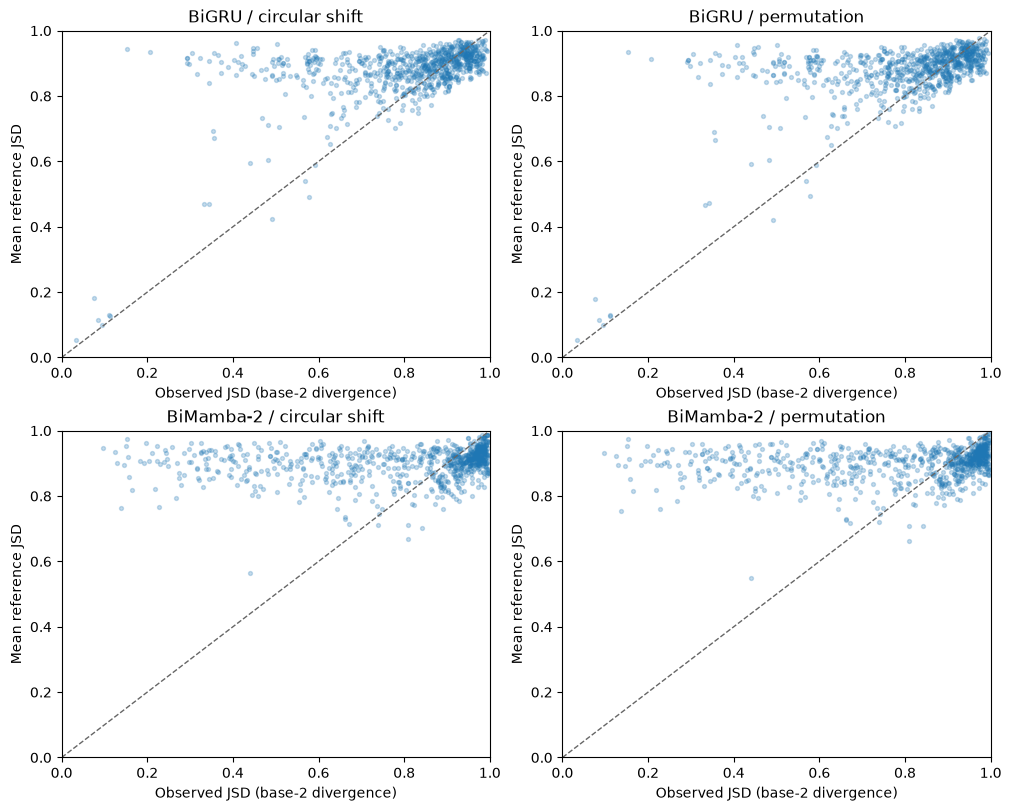

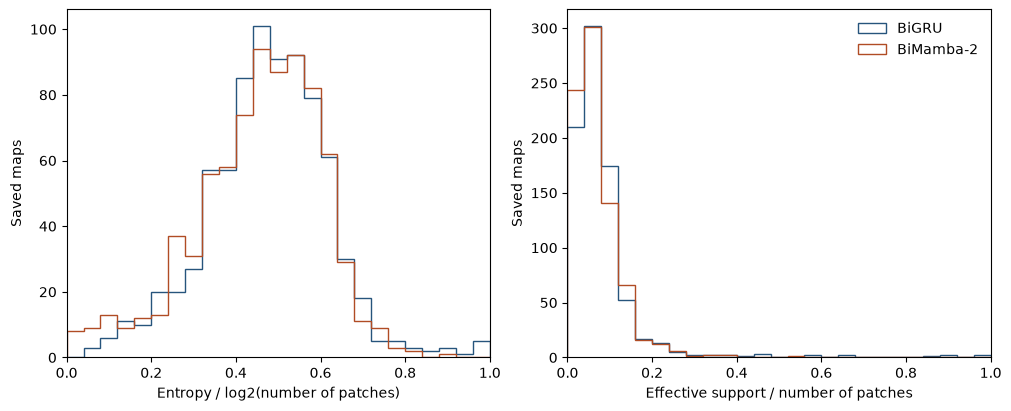

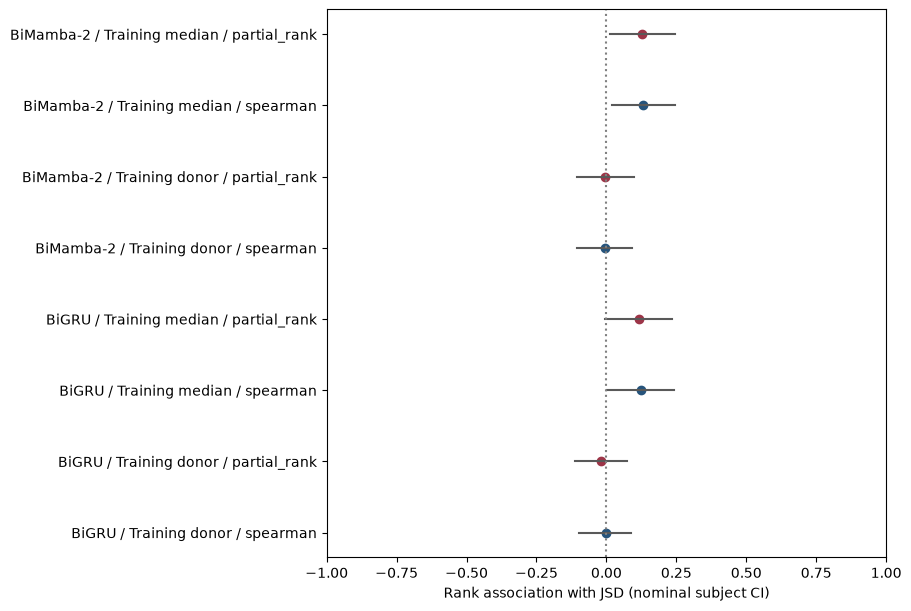

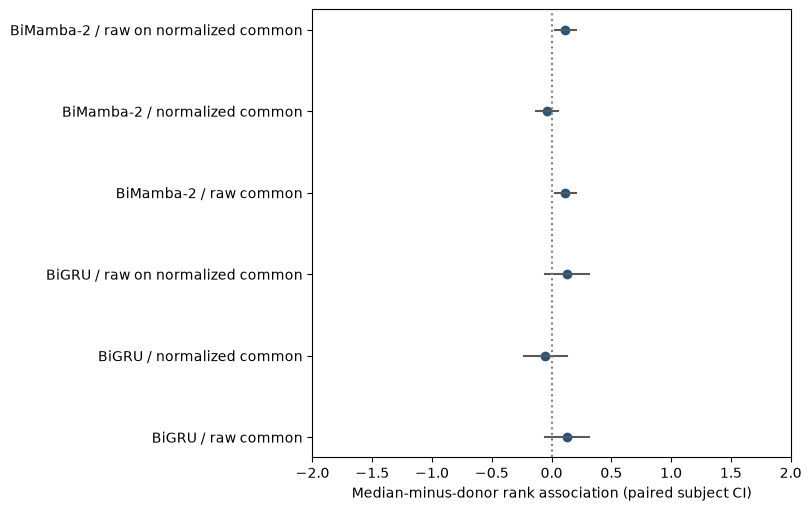

In [15]:
ARM_LABEL={'gru':'BiGRU','mamba2':'BiMamba-2'}
MASK_LABEL={'train_median':'Training median','train_donor':'Training donor'}
fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
for i,arm in enumerate(ARMS):
    for j,reference in enumerate(('circular_shift','permutation')):
        g=reference_summary[(reference_summary.architecture==arm)&(reference_summary.reference==reference)]
        axes[i,j].scatter(g.actual_jsd,g.reference_mean,s=8,alpha=.25,rasterized=True)
        axes[i,j].plot([0,1],[0,1],color='.4',ls='--',lw=1)
        axes[i,j].set(xlim=(0,1),ylim=(0,1),xlabel='Observed JSD (base-2 divergence)',
            ylabel='Mean reference JSD',title=ARM_LABEL[arm]+' / '+reference.replace('_',' '))
save_figure(fig,'observed_vs_reference_jsd')
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for arm,color in zip(ARMS,('#26547c','#b04c24')):
    g=concentration[concentration.architecture==arm]
    axes[0].hist(g.normalized_entropy,bins=np.linspace(0,1,26),histtype='step',label=ARM_LABEL[arm],color=color)
    axes[1].hist(g.effective_support_fraction,bins=np.linspace(0,1,26),histtype='step',label=ARM_LABEL[arm],color=color)
axes[0].set(xlabel='Entropy / log2(number of patches)',ylabel='Saved maps',xlim=(0,1))
axes[1].set(xlabel='Effective support / number of patches',ylabel='Saved maps',xlim=(0,1))
axes[1].legend(frameon=False)
save_figure(fig,'attention_concentration')
fig,ax=plt.subplots(figsize=(9,6),layout='constrained')
g=conditional[(conditional.scope=='raw_native_support')&(conditional.adjustment=='abs_delta_logit')]
labels=[]
for i,row in enumerate(g.itertuples(index=False)):
    if np.isfinite(row.estimate):
        ax.plot(row.estimate,i,'o',color='#26547c' if row.estimator=='weighted_spearman' else '#9d3548')
        if np.isfinite(row.ci_low):ax.plot([row.ci_low,row.ci_high],[i,i],color='.35')
    labels.append(ARM_LABEL[row.architecture]+' / '+MASK_LABEL[row.masker]+' / '+row.estimator.replace('weighted_',''))
ax.set_yticks(range(len(labels)),labels);ax.axvline(0,color='.5',ls=':')
ax.set(xlabel='Rank association with JSD (nominal subject CI)',xlim=(-1,1))
save_figure(fig,'output_change_sensitivity')
fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
g=replacement_ci[replacement_ci.adjustment=='none']
labels=[]
for i,row in enumerate(g.itertuples(index=False)):
    if np.isfinite(row.estimate):
        ax.plot(row.estimate,i,'o',color='#26547c')
        if np.isfinite(row.ci_low):ax.plot([row.ci_low,row.ci_high],[i,i],color='.35')
    labels.append(ARM_LABEL[row.architecture]+' / '+row.scope.replace('_',' '))
ax.set_yticks(range(len(labels)),labels);ax.axvline(0,color='.5',ls=':')
ax.set(xlabel='Median-minus-donor rank association (paired subject CI)',xlim=(-2,2))
save_figure(fig,'replacement_contrast')

In [16]:
check(source_digest(NOTEBOOK)==SOURCE_DIGEST,'new notebook scientific source unchanged')
inventory=[]
for path,before in sorted(tracked.items(),key=lambda item:str(item[0])):
    after=file_hash(path)
    inventory.append(dict(path=str(path.relative_to(ROOT)),sha256_before=before,
                          sha256_after=after,unchanged=before==after))
inventory=pd.DataFrame(inventory)
inventory.to_csv(OUT/'input_inventory.csv',index=False)
check(inventory.unchanged.all(),'all original input/source files unchanged')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
run_manifest.update(completion_status='complete',completed_utc=datetime.now(timezone.utc).isoformat(),
    scientific_source=str(NOTEBOOK.relative_to(ROOT)),notebook_source_sha256=SOURCE_DIGEST,
    source_pins_sha256=file_hash(PLAN/'source_pins.json'),protocol_sha256=file_hash(PLAN/'PROTOCOL.md'),
    versions={name:version(name) for name in ('numpy','pandas','scipy','matplotlib')},
    python=platform.python_version(),tables=sorted(p.name for p in OUT.glob('*.csv')),
    figures=sorted(p.name for p in FIG.glob('*')),old_preregistration_changed=False,
    alignment_checks_total=len(checks),alignment_checks_passed=sum(int(c['passed']) for c in checks),
    n_input_files_tracked=len(inventory),bank=dict(cohort=recipe['cohort'],architectures=list(ARMS),
        seeds=list(SEEDS),n_checkpoints=len(models),n_records=len(records),n_subjects=len(subjects)))
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('COMPLETE:',OUT)
print('Additional exploratory results; historical estimates and manuscript untouched.')

COMPLETE: /home/agribychaniago/Python Projects/Skripsi/results/attention_audit_diagnostics/20261016T045207091905Z
Additional exploratory results; historical estimates and manuscript untouched.
